# 💳 Credit Scoring Model — CodeAlpha ML Internship (Task 1)

**Objective:** predict an individual's creditworthiness (will they default next month?) from past financial data.

**Dataset:** [Default of Credit Card Clients](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset) — 30,000 clients, credit limit, 6 months of bills (debt), payments and repayment status (payment history).

**Models:** Logistic Regression · Decision Tree · Random Forest   |   **Metrics:** Precision · Recall · F1 · ROC-AUC

## 1. Setup — imports & settings

In [15]:
import glob, json, os, warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
SEED = 42
N_ITER = 15                                                   # RF random-search iterations
INPUT = "/kaggle/input" if os.path.exists("/kaggle/input") else "."
OUT = "/kaggle/working/outputs" if os.path.exists("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)

PAY_STATUS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT = [f"PAY_AMT{i}" for i in range(1, 7)]
RAW_COLS = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"] + PAY_STATUS + BILL + PAY_AMT

## 2. Load the dataset
The loader searches `/kaggle/input` for the CSV that has the `default.payment.next.month` column, so it works whatever the input folder is called. `SEX` and `MARRIAGE` are later excluded (protected attributes).

In [16]:
def find_data():
    files = glob.glob(f"{INPUT}/**/*.csv", recursive=True) + glob.glob(f"{INPUT}/**/*.xls*", recursive=True)
    for f in files:
        df = pd.read_excel(f, header=1) if f.lower().endswith((".xls", ".xlsx")) else pd.read_csv(f)
        if any("default" in str(c).lower() for c in df.columns):
            print("Using:", f)
            return df
    raise FileNotFoundError("Add the 'default-of-credit-card-clients-dataset' as notebook input")


df = find_data()
df = df.drop(columns=[c for c in df.columns if str(c).upper() == "ID"])
target = [c for c in df.columns if "default" in str(c).lower()][0]
y = df.pop(target).astype(int)
X_raw = df.copy()
X_raw.columns = RAW_COLS
print(f"{len(X_raw)} clients | default rate = {y.mean():.2%}")

Using: /kaggle/input/datasets/uciml/default-of-credit-card-clients-dataset/UCI_Credit_Card.csv
30000 clients | default rate = 22.12%


## 3. Feature engineering
Raw monthly records are turned into credit-risk signals:

| Group | Features |
|---|---|
| Payment history | recent delay, max delay, average delay, months late, delay trend |
| Debt / utilisation | bill ÷ limit (recent, average, max), debt growth, log average bill |
| Repayment capacity | total paid ÷ total billed, worst monthly payment ratio, zero-payment months |

In [17]:
def slog(s):
    return np.sign(s) * np.log1p(np.abs(s))


def engineer_features(X):
    X = X.copy()
    X["EDUCATION"] = X["EDUCATION"].replace({0: 4, 5: 4, 6: 4})      # undocumented codes -> others
    f = pd.DataFrame(index=X.index)
    limit = X["LIMIT_BAL"].clip(lower=1)
    delay = X[PAY_STATUS].clip(lower=0)                               # -2/-1/0 = paid on time
    # payment history
    f["recent_delay"] = delay["PAY_0"]
    f["max_delay"] = delay.max(axis=1)
    f["avg_delay"] = delay.mean(axis=1)
    f["months_delayed"] = (delay > 0).sum(axis=1)
    f["delay_trend"] = delay[PAY_STATUS[:3]].mean(axis=1) - delay[PAY_STATUS[3:]].mean(axis=1)
    for c in PAY_STATUS:
        f[c] = X[c]
    # debt / utilisation
    f["log_limit"] = np.log1p(X["LIMIT_BAL"])
    f["utilization_recent"] = X["BILL_AMT1"] / limit
    f["utilization_avg"] = X[BILL].mean(axis=1) / limit
    f["utilization_max"] = X[BILL].max(axis=1) / limit
    f["debt_growth"] = (X["BILL_AMT1"] - X["BILL_AMT6"]) / limit
    f["log_avg_bill"] = slog(X[BILL].mean(axis=1))
    # repayment capacity
    tb, tp = X[BILL].sum(axis=1), X[PAY_AMT].sum(axis=1)
    f["pay_to_bill_ratio"] = (tp / tb.where(tb > 0)).fillna(1.0).clip(0, 5)
    ratios = [(X[PAY_AMT[i]] / X[BILL[i + 1]].where(X[BILL[i + 1]] > 0)).fillna(1.0).clip(0, 5) for i in range(5)]
    f["min_monthly_pay_ratio"] = pd.concat(ratios, axis=1).min(axis=1)
    f["zero_payment_months"] = (X[PAY_AMT] == 0).sum(axis=1)
    f["log_avg_payment"] = np.log1p(X[PAY_AMT].mean(axis=1))
    # non-protected demographics (SEX, MARRIAGE excluded for fairness)
    f["AGE"] = X["AGE"]
    f["EDUCATION"] = X["EDUCATION"].astype(int)
    return f


X = engineer_features(X_raw)
print("Engineered features:", X.shape[1])

Engineered features: 23


## 4. Train/test split & model pipelines
80/20 stratified split. Each model is a Pipeline (scaling + one-hot encoding → classifier); class weights handle the 78/22 imbalance.

In [18]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pre = ColumnTransformer([("num", StandardScaler(), [c for c in X.columns if c != "EDUCATION"]),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), ["EDUCATION"])])
models = {
    "Logistic Regression": Pipeline([("pre", pre), ("clf", LogisticRegression(
        max_iter=2000, class_weight="balanced", C=0.5, random_state=SEED))]),
    "Decision Tree": Pipeline([("pre", pre), ("clf", DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([("pre", pre), ("clf", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]),
}

## 5. Cross-validation (5-fold ROC-AUC on the training set)

In [19]:
print("\n[1] 5-fold CV ROC-AUC (train set)")
for name, m in models.items():
    s = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"  {name:20s} {s.mean():.4f} ± {s.std():.4f}")


[1] 5-fold CV ROC-AUC (train set)
  Logistic Regression  0.7773 ± 0.0052
  Decision Tree        0.7691 ± 0.0048
  Random Forest        0.7805 ± 0.0051


## 6. Hyper-parameter tuning — Random Forest (RandomizedSearchCV)

In [20]:
print("\n[2] Tuning Random Forest ...")
search = RandomizedSearchCV(models["Random Forest"], {
    "clf__n_estimators": [200, 300, 500], "clf__max_depth": [8, 12, 16, None],
    "clf__min_samples_leaf": [2, 5, 10, 20], "clf__max_features": ["sqrt", 0.3, 0.5]},
    n_iter=N_ITER, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=SEED)
search.fit(X_tr, y_tr)
models["Random Forest"] = search.best_estimator_
print("  best params:", search.best_params_, f"CV AUC={search.best_score_:.4f}")


[2] Tuning Random Forest ...
  best params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 10, 'clf__max_features': 0.3, 'clf__max_depth': 8} CV AUC=0.7872


## 7. Decision threshold & test-set evaluation
The threshold that maximises F1 is chosen on **out-of-fold training predictions**, so the test set is never used for tuning. Metrics: Precision, Recall, F1-Score, ROC-AUC.

In [21]:
def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])


print("\n[3] Test-set results (threshold = max F1 on out-of-fold TRAIN predictions)")
results, test_proba = {}, {}
for name, m in models.items():
    oof = cross_val_predict(m, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    thr = best_f1_threshold(y_tr, oof)
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    pred = (p >= thr).astype(int)
    test_proba[name] = p
    results[name] = {"threshold": round(thr, 4), "precision": round(precision_score(y_te, pred), 4),
                     "recall": round(recall_score(y_te, pred), 4), "f1": round(f1_score(y_te, pred), 4),
                     "roc_auc": round(roc_auc_score(y_te, p), 4)}
table = pd.DataFrame(results).T
print(table.to_string())
table.to_csv(f"{OUT}/model_comparison.csv")

best = table["roc_auc"].astype(float).idxmax()
thr = results[best]["threshold"]
pred = (test_proba[best] >= thr).astype(int)
print(f"\nBest model: {best}\n")
print(classification_report(y_te, pred, target_names=["No default", "Default"]))


[3] Test-set results (threshold = max F1 on out-of-fold TRAIN predictions)
                     threshold  precision  recall      f1  roc_auc
Logistic Regression     0.5378     0.4796  0.5848  0.5270   0.7635
Decision Tree           0.5869     0.5276  0.5335  0.5305   0.7633
Random Forest           0.5225     0.5158  0.5765  0.5445   0.7801

Best model: Random Forest

              precision    recall  f1-score   support

  No default       0.88      0.85      0.86      4673
     Default       0.52      0.58      0.54      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.71      0.70      6000
weighted avg       0.80      0.79      0.79      6000



## 8. ROC curves

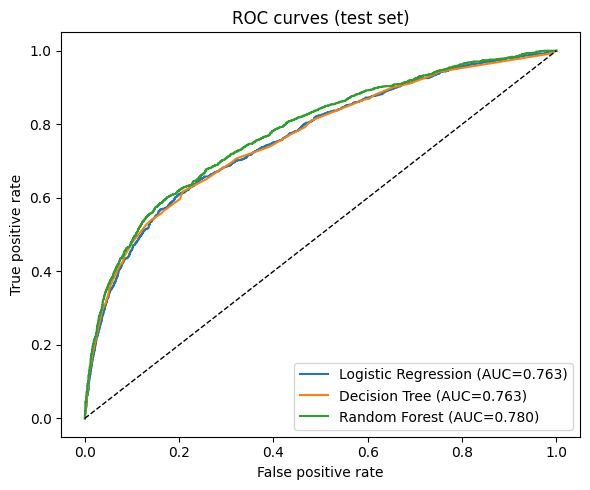

In [22]:
plt.figure(figsize=(6, 5))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (test set)")
plt.legend(); plt.tight_layout(); plt.savefig(f"{OUT}/roc_curves.png", dpi=150); plt.show()

## 9. Confusion matrix (best model)

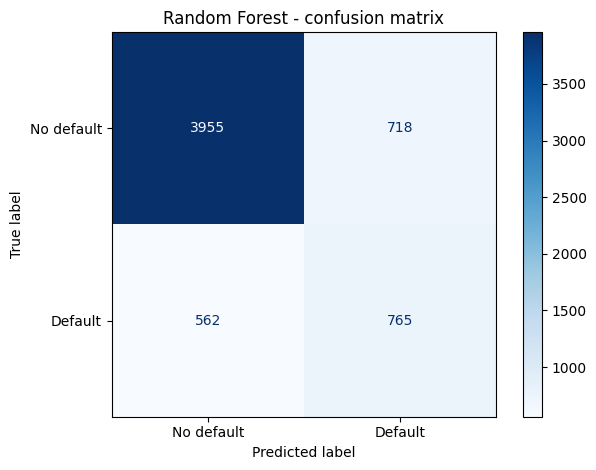

In [23]:
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["No default", "Default"]).plot(cmap="Blues")
plt.title(f"{best} - confusion matrix"); plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150); plt.show()

## 10. Feature importance — what drives default risk?

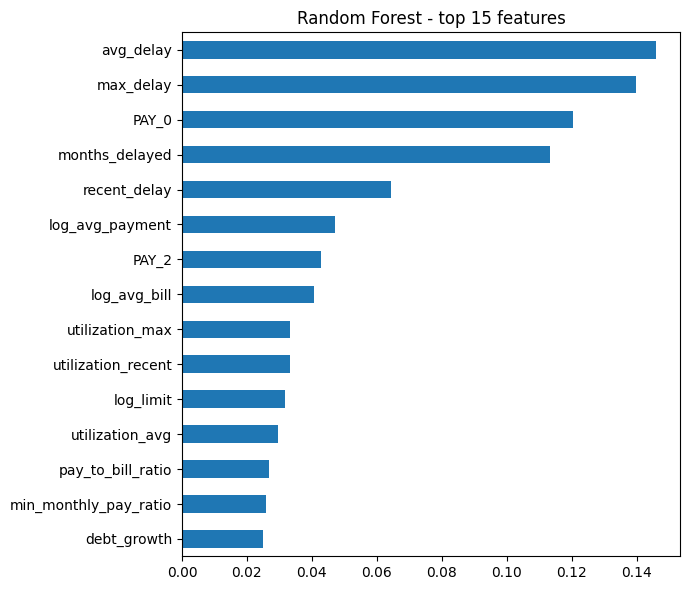

In [24]:
rf = models["Random Forest"]
imp = pd.Series(rf.named_steps["clf"].feature_importances_,
                index=[n.split("__", 1)[1] for n in rf.named_steps["pre"].get_feature_names_out()])
imp.sort_values().tail(15).plot.barh(figsize=(7, 6), title="Random Forest - top 15 features")
plt.tight_layout(); plt.savefig(f"{OUT}/feature_importance.png", dpi=150); plt.show()

## 11. Credit scores (300–850) & save model
Default probability is mapped to an illustrative credit score with an APPROVE / HIGH RISK decision.

In [25]:
p = models[best].predict_proba(X_te.head(10))[:, 1]
print(pd.DataFrame({"p_default": p.round(3),
                    "credit_score(300-850)": np.round(300 + (1 - p) * 550).astype(int),
                    "decision": np.where(p >= thr, "HIGH RISK", "APPROVE"),
                    "actual_default": y_te.head(10).values}).to_string(index=False))

joblib.dump({"model": models[best], "threshold": thr, "features": list(X.columns)}, f"{OUT}/credit_model.joblib")
json.dump({"best_model": best, "results": results}, open(f"{OUT}/metrics.json", "w"), indent=2)
print(f"\nSaved everything to {OUT}/")

 p_default  credit_score(300-850) decision  actual_default
     0.317                    676  APPROVE               0
     0.307                    681  APPROVE               0
     0.390                    635  APPROVE               0
     0.333                    667  APPROVE               1
     0.168                    757  APPROVE               0
     0.513                    568  APPROVE               0
     0.310                    680  APPROVE               0
     0.134                    776  APPROVE               0
     0.192                    744  APPROVE               0
     0.170                    756  APPROVE               0

Saved everything to /kaggle/working/outputs/
